In [1]:

import pandas as pd

# Repositorio público del Laboratorio 4
base_url = "https://raw.githubusercontent.com/Brianrp19/laboratorio4-mineria-datos/main/datos/origen/"

# Archivos originales del Proyecto 1
archivos = [
    "Album", "Artist", "Customer", "Employee",
    "Genre", "Invoice", "InvoiceLine",
    "MediaType", "Playlist", "PlaylistTrack", "Track"
]

# Leer los CSV directamente desde GitHub
tablas = {}

for nombre in archivos:
    url = base_url + nombre + ".csv"
    tablas[nombre] = pd.read_csv(url)
    print(f"{nombre}: {tablas[nombre].shape[0]} filas y {tablas[nombre].shape[1]} columnas")


Album: 347 filas y 3 columnas
Artist: 275 filas y 2 columnas
Customer: 59 filas y 13 columnas
Employee: 8 filas y 15 columnas
Genre: 25 filas y 2 columnas
Invoice: 412 filas y 9 columnas
InvoiceLine: 2240 filas y 5 columnas
MediaType: 5 filas y 2 columnas
Playlist: 18 filas y 2 columnas
PlaylistTrack: 8715 filas y 2 columnas
Track: 3503 filas y 9 columnas


# Laboratorio 4 — Minería de Datos

## Análisis Exploratorio de Datos (EDA)

**Dataset:** Chinook — Proyecto 1

**Objetivo:** Analizar la estructura, calidad y comportamiento de los datos originales de Chinook utilizando Python en Google Colab.

Los archivos CSV se cargan directamente desde el repositorio público de GitHub, sin modificar los datos originales.

### Etapa 1. Exploración inicial de los datos

In [2]:

# Revisar la calidad inicial de las 11 tablas

for nombre, df in tablas.items():
    print(f"\n--- {nombre} ---")
    print("Filas:", df.shape[0])
    print("Columnas:", df.shape[1])
    print("Valores nulos:", df.isnull().sum().sum())
    print("Filas duplicadas:", df.duplicated().sum())



--- Album ---
Filas: 347
Columnas: 3
Valores nulos: 0
Filas duplicadas: 0

--- Artist ---
Filas: 275
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Customer ---
Filas: 59
Columnas: 13
Valores nulos: 130
Filas duplicadas: 0

--- Employee ---
Filas: 8
Columnas: 15
Valores nulos: 1
Filas duplicadas: 0

--- Genre ---
Filas: 25
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Invoice ---
Filas: 412
Columnas: 9
Valores nulos: 230
Filas duplicadas: 0

--- InvoiceLine ---
Filas: 2240
Columnas: 5
Valores nulos: 0
Filas duplicadas: 0

--- MediaType ---
Filas: 5
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Playlist ---
Filas: 18
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- PlaylistTrack ---
Filas: 8715
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Track ---
Filas: 3503
Columnas: 9
Valores nulos: 978
Filas duplicadas: 0


In [3]:

# Identificar las columnas que contienen valores nulos

for nombre in ["Customer", "Employee", "Invoice", "Track"]:
    df = tablas[nombre]

    resumen = pd.DataFrame({
        "Valores nulos": df.isnull().sum(),
        "Porcentaje (%)": (df.isnull().mean() * 100).round(2)
    })

    print(f"\n--- {nombre} ---")

    display(resumen[resumen["Valores nulos"] > 0])



--- Customer ---


,Valores nulos,Porcentaje (%)
Company,49,83.05
State,29,49.15
PostalCode,4,6.78
Phone,1,1.69
Fax,47,79.66



--- Employee ---


,Valores nulos,Porcentaje (%)
ReportsTo,1,12.5



--- Invoice ---


,Valores nulos,Porcentaje (%)
BillingState,202,49.03
BillingPostalCode,28,6.80



--- Track ---


,Valores nulos,Porcentaje (%)
Composer,978,27.92


In [5]:

# Verificar las relaciones entre las tablas

relaciones = [
    ("InvoiceLine", "InvoiceId", "Invoice", "InvoiceId"),
    ("InvoiceLine", "TrackId", "Track", "TrackId"),
    ("Invoice", "CustomerId", "Customer", "CustomerId"),
    ("Track", "GenreId", "Genre", "GenreId")
]

for origen, columna_origen, destino, columna_destino in relaciones:
    # Identificar registros sin correspondencia
    sin_relacion = ~tablas[origen][columna_origen].isin(
        tablas[destino][columna_destino]
    )

    # Comprobar identificadores repetidos en la tabla destino
    repetidos = tablas[destino][columna_destino].duplicated().sum()

    print(f"\n{origen} -> {destino}")
    print("Registros sin relación:", sin_relacion.sum())
    print("Identificadores repetidos en destino:", repetidos)



InvoiceLine -> Invoice
Registros sin relación: 0
Identificadores repetidos en destino: 0

InvoiceLine -> Track
Registros sin relación: 0
Identificadores repetidos en destino: 0

Invoice -> Customer
Registros sin relación: 0
Identificadores repetidos en destino: 0

Track -> Genre
Registros sin relación: 0
Identificadores repetidos en destino: 0


In [6]:

# Construcción del dataset analítico de ventas

ventas = tablas["InvoiceLine"].copy()

# Agregar información de las facturas
ventas = ventas.merge(
    tablas["Invoice"][["InvoiceId", "CustomerId", "InvoiceDate", "BillingCountry"]],
    on="InvoiceId",
    how="left",
    validate="many_to_one"
)

# Agregar información de las canciones
canciones = tablas["Track"][["TrackId", "Name", "GenreId", "Milliseconds"]].copy()
canciones = canciones.rename(columns={"Name": "Cancion"})

ventas = ventas.merge(
    canciones,
    on="TrackId",
    how="left",
    validate="many_to_one"
)

# Agregar el género musical
generos = tablas["Genre"][["GenreId", "Name"]].copy()
generos = generos.rename(columns={"Name": "Genero"})

ventas = ventas.merge(
    generos,
    on="GenreId",
    how="left",
    validate="many_to_one"
)

# Agregar el país del cliente
ventas = ventas.merge(
    tablas["Customer"][["CustomerId", "Country"]],
    on="CustomerId",
    how="left",
    validate="many_to_one"
)

# Convertir la fecha
ventas["InvoiceDate"] = pd.to_datetime(ventas["InvoiceDate"])

# Calcular el importe de cada línea de venta
ventas["ImporteLinea"] = ventas["UnitPrice"] * ventas["Quantity"]

# Comprobar que no perdimos ni multiplicamos registros
assert len(ventas) == len(tablas["InvoiceLine"])

print("Filas del dataset:", ventas.shape[0])
print("Columnas del dataset:", ventas.shape[1])
print("Facturas diferentes:", ventas["InvoiceId"].nunique())
print("Clientes diferentes:", ventas["CustomerId"].nunique())

display(ventas.head())


Filas del dataset: 2240
Columnas del dataset: 14
Facturas diferentes: 412
Clientes diferentes: 59


,InvoiceLineId,InvoiceId,TrackId,UnitPrice,Quantity,CustomerId,InvoiceDate,BillingCountry,Cancion,GenreId,Milliseconds,Genero,Country,ImporteLinea
0,1,1,2,0.99,1,2,2009-01-01,Germany,Balls to the Wall,1,342562,Rock,Germany,0.99
1,2,1,4,0.99,1,2,2009-01-01,Germany,Restless and Wild,1,252051,Rock,Germany,0.99
2,3,2,6,0.99,1,4,2009-01-02,Norway,Put The Finger On You,1,205662,Rock,Norway,0.99
3,4,2,8,0.99,1,4,2009-01-02,Norway,Inject The Venom,1,210834,Rock,Norway,0.99
4,5,2,10,0.99,1,4,2009-01-02,Norway,Evil Walks,1,263497,Rock,Norway,0.99


In [7]:

# Validación del dataset analítico

print("Valores nulos por columna:")
print(ventas.isnull().sum())

print("\nLíneas de venta duplicadas:")
print(ventas["InvoiceLineId"].duplicated().sum())

# Comprobar los importes de las ventas
total_calculado = ventas["ImporteLinea"].sum()
total_facturas = tablas["Invoice"]["Total"].sum()

print("\nTotal calculado:", round(total_calculado, 2))
print("Total registrado en facturas:", round(total_facturas, 2))
print("Diferencia:", round(total_calculado - total_facturas, 2))

# Estadísticas descriptivas
display(
    ventas[["UnitPrice", "Quantity", "Milliseconds", "ImporteLinea"]]
    .describe()
    .round(2)
)


Valores nulos por columna:
InvoiceLineId     0
InvoiceId         0
TrackId           0
UnitPrice         0
Quantity          0
CustomerId        0
InvoiceDate       0
BillingCountry    0
Cancion           0
GenreId           0
Milliseconds      0
Genero            0
Country           0
ImporteLinea      0
dtype: int64

Líneas de venta duplicadas:
0

Total calculado: 2328.6
Total registrado en facturas: 2328.6
Diferencia: 0.0


,UnitPrice,Quantity,Milliseconds,ImporteLinea
count,2240.00,2240.0,2240.00,2240.00
mean,1.04,1.0,375435.99,1.04
std,0.22,0.0,507221.98,0.22
min,0.99,1.0,6373.00,0.99
25%,0.99,1.0,205981.50,0.99
50%,0.99,1.0,256443.50,0.99
75%,0.99,1.0,321136.00,0.99
max,1.99,1.0,5286953.00,1.99



## Etapa 2 — Calidad y tratamiento de datos
**Responsable:** Cristopher

En esta etapa se analizan los valores faltantes del conjunto
de datos, se renombran las columnas a español y se crean
funciones para tratar información incompleta.

Los archivos originales no se modifican.


In [13]:

# Crear una copia para conservar el dataset original
ventas_tratadas = ventas.copy()

columnas_espanol = {
    "InvoiceLineId": "IdLineaFactura",
    "InvoiceId": "IdFactura",
    "TrackId": "IdCancion",
    "UnitPrice": "PrecioUnitario",
    "Quantity": "Cantidad",
    "CustomerId": "IdCliente",
    "InvoiceDate": "FechaFactura",
    "BillingCountry": "PaisFacturacion",
    "GenreId": "IdGenero",
    "Milliseconds": "DuracionMilisegundos",
    "Country": "PaisCliente"
}

ventas_tratadas.rename(
    columns=columnas_espanol,
    inplace=True
)

print("Columnas del dataset:")
print(ventas_tratadas.columns.tolist())

display(ventas_tratadas.head())


Columnas del dataset:
['IdLineaFactura', 'IdFactura', 'IdCancion', 'PrecioUnitario', 'Cantidad', 'IdCliente', 'FechaFactura', 'PaisFacturacion', 'Cancion', 'IdGenero', 'DuracionMilisegundos', 'Genero', 'PaisCliente', 'ImporteLinea']


,IdLineaFactura,IdFactura,IdCancion,PrecioUnitario,Cantidad,IdCliente,FechaFactura,PaisFacturacion,Cancion,IdGenero,DuracionMilisegundos,Genero,PaisCliente,ImporteLinea
0,1,1,2,0.99,1,2,2009-01-01,Germany,Balls to the Wall,1,342562,Rock,Germany,0.99
1,2,1,4,0.99,1,2,2009-01-01,Germany,Restless and Wild,1,252051,Rock,Germany,0.99
2,3,2,6,0.99,1,4,2009-01-02,Norway,Put The Finger On You,1,205662,Rock,Norway,0.99
3,4,2,8,0.99,1,4,2009-01-02,Norway,Inject The Venom,1,210834,Rock,Norway,0.99
4,5,2,10,0.99,1,4,2009-01-02,Norway,Evil Walks,1,263497,Rock,Norway,0.99


In [14]:

import pandas as pd

# Analizar los nulos del dataset de ventas
resumen_ventas = pd.DataFrame({
    "Nulos": ventas_tratadas.isna().sum(),
    "Porcentaje": (
        ventas_tratadas.isna().mean() * 100
    ).round(2)
})

print("Valores nulos en ventas:")
display(resumen_ventas)

# Analizar las columnas con nulos en los CSV originales
for nombre, df in tablas.items():
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]

    if not nulos.empty:
        print(f"\nTabla: {nombre}")
        display(pd.DataFrame({
            "Nulos": nulos,
            "Porcentaje": (
                nulos / len(df) * 100
            ).round(2)
        }))


Valores nulos en ventas:


,Nulos,Porcentaje
IdLineaFactura,0,0.0
IdFactura,0,0.0
IdCancion,0,0.0
PrecioUnitario,0,0.0
Cantidad,0,0.0
IdCliente,0,0.0
FechaFactura,0,0.0
PaisFacturacion,0,0.0
Cancion,0,0.0
IdGenero,0,0.0



Tabla: Customer


,Nulos,Porcentaje
Company,49,83.05
State,29,49.15
PostalCode,4,6.78
Phone,1,1.69
Fax,47,79.66



Tabla: Employee


,Nulos,Porcentaje
ReportsTo,1,12.5



Tabla: Invoice


,Nulos,Porcentaje
BillingState,202,49.03
BillingPostalCode,28,6.80



Tabla: Track


,Nulos,Porcentaje
Composer,978,27.92


In [15]:

def imputar_categorica(df, columna, valor="No informado"):
    """Rellena valores faltantes de una columna categórica."""
    resultado = df.copy()
    resultado[columna] = resultado[columna].fillna(valor)
    return resultado


def imputar_numerica_mediana(df, columna):
    """Rellena valores numéricos faltantes con la mediana."""
    resultado = df.copy()
    mediana = resultado[columna].median()
    resultado[columna] = resultado[columna].fillna(mediana)
    return resultado


# Aplicar imputación sobre una columna original con nulos
tracks_tratados = imputar_categorica(
    tablas["Track"],
    "Composer"
)

print("Nulos originales en Composer:",
      tablas["Track"]["Composer"].isna().sum())

print("Nulos después de imputar:",
      tracks_tratados["Composer"].isna().sum())


Nulos originales en Composer: 978
Nulos después de imputar: 0


In [16]:

# Verificar que no se perdieron registros
assert len(ventas_tratadas) == len(ventas)

# Verificar que los importes no cambiaron
assert abs(
    ventas_tratadas["ImporteLinea"].sum()
    - ventas["ImporteLinea"].sum()
) < 0.000001

# Confirmar que el dataset analítico no contiene nulos
assert ventas_tratadas.isna().sum().sum() == 0

print("Validaciones completadas correctamente.")
print("Registros conservados:", len(ventas_tratadas))
print("Total de ventas:", round(
    ventas_tratadas["ImporteLinea"].sum(), 2
))


Validaciones completadas correctamente.
Registros conservados: 2240
Total de ventas: 2328.6



## Etapa 2.1 — Visualización de valores faltantes y atípicos

En esta sección se representan gráficamente los valores
faltantes de los archivos originales y se analizan posibles
valores atípicos en las variables numéricas del conjunto
de ventas.

El objetivo es identificar problemas de calidad sin eliminar
información válida de manera innecesaria.


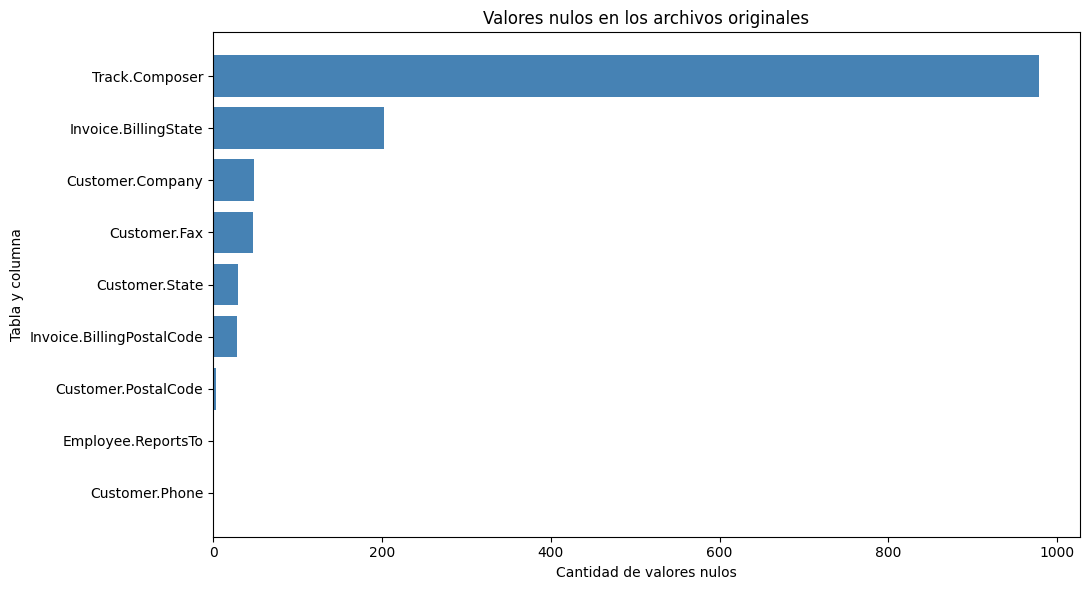

In [17]:

import matplotlib.pyplot as plt
import pandas as pd

# Reunir los valores nulos de los CSV originales
datos_nulos = []

for nombre_tabla, df in tablas.items():
    for columna in df.columns:
        cantidad = df[columna].isna().sum()

        if cantidad > 0:
            datos_nulos.append({
                "Tabla": nombre_tabla,
                "Columna": columna,
                "Nulos": cantidad,
                "Porcentaje": cantidad / len(df) * 100
            })

nulos_grafico = pd.DataFrame(datos_nulos)

# Etiqueta para identificar tabla y columna
nulos_grafico["Variable"] = (
    nulos_grafico["Tabla"] + "." +
    nulos_grafico["Columna"]
)

# Ordenar de menor a mayor cantidad
nulos_grafico = nulos_grafico.sort_values("Nulos")

plt.figure(figsize=(11, 6))

plt.barh(
    nulos_grafico["Variable"],
    nulos_grafico["Nulos"],
    color="steelblue"
)

plt.title("Valores nulos en los archivos originales")
plt.xlabel("Cantidad de valores nulos")
plt.ylabel("Tabla y columna")

plt.tight_layout()
plt.show()


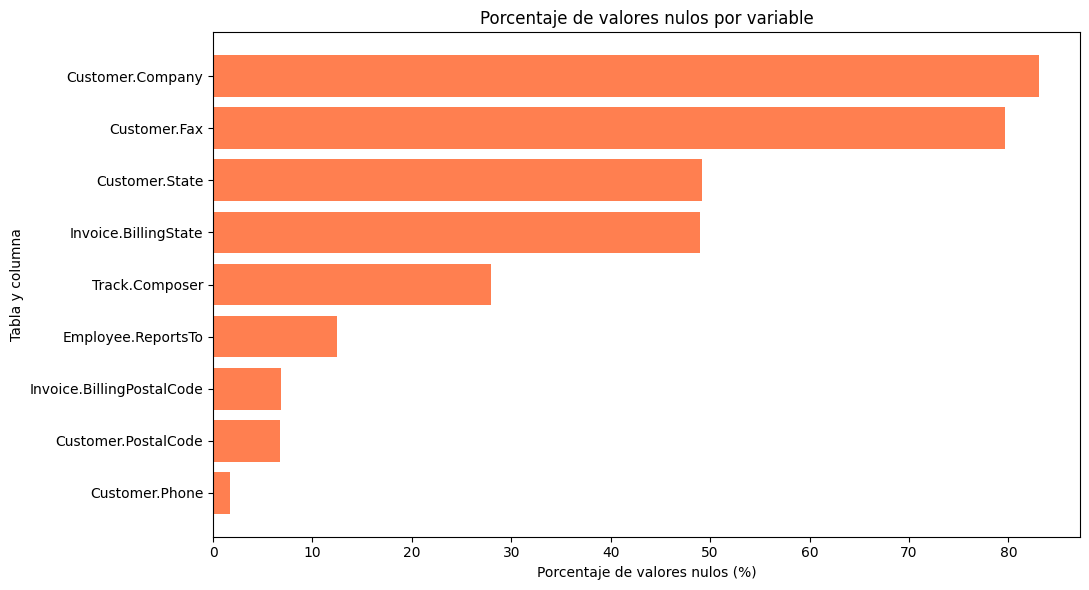

In [18]:

nulos_porcentaje = nulos_grafico.sort_values(
    "Porcentaje"
)

plt.figure(figsize=(11, 6))

plt.barh(
    nulos_porcentaje["Variable"],
    nulos_porcentaje["Porcentaje"],
    color="coral"
)

plt.title("Porcentaje de valores nulos por variable")
plt.xlabel("Porcentaje de valores nulos (%)")
plt.ylabel("Tabla y columna")

plt.tight_layout()
plt.show()


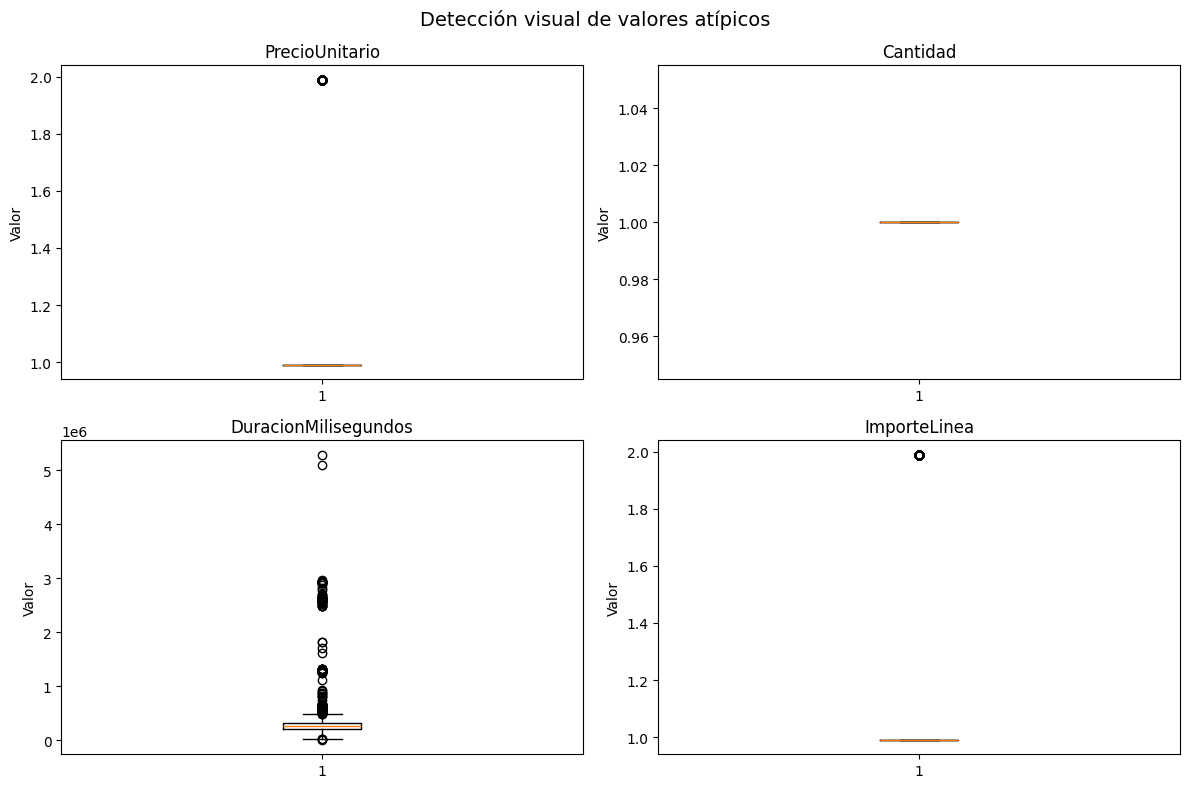

In [19]:

columnas_numericas = [
    "PrecioUnitario",
    "Cantidad",
    "DuracionMilisegundos",
    "ImporteLinea"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, columna in zip(axes.flat, columnas_numericas):
    ax.boxplot(
        ventas_tratadas[columna].dropna(),
        vert=True
    )

    ax.set_title(columna)
    ax.set_ylabel("Valor")

plt.suptitle(
    "Detección visual de valores atípicos",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [20]:

def detectar_atipicos_iqr(df, columna):
    datos = df[columna].dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = datos[
        (datos < limite_inferior) |
        (datos > limite_superior)
    ]

    return {
        "Variable": columna,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "LimiteInferior": limite_inferior,
        "LimiteSuperior": limite_superior,
        "Atipicos": len(atipicos),
        "Porcentaje": round(
            len(atipicos) / len(datos) * 100, 2
        )
    }


resultados_iqr = []

for columna in columnas_numericas:
    resultados_iqr.append(
        detectar_atipicos_iqr(
            ventas_tratadas, columna
        )
    )

resumen_atipicos = pd.DataFrame(resultados_iqr)

display(resumen_atipicos)


,Variable,Q1,Q3,IQR,LimiteInferior,LimiteSuperior,Atipicos,Porcentaje
0,PrecioUnitario,0.99,0.99,0.0,0.99,0.99,111,4.96
1,Cantidad,1.00,1.00,0.0,1.00,1.00,0,0.00
2,DuracionMilisegundos,205981.50,321136.00,115154.5,33249.75,493867.75,198,8.84
3,ImporteLinea,0.99,0.99,0.0,0.99,0.99,111,4.96


### Interpretación de los valores faltantes y atípicos

**Análisis de valores nulos**

Los gráficos permiten identificar las columnas de los archivos originales de Chinook que presentan información faltante, tanto en cantidades absolutas como en porcentajes. Esto facilita reconocer cuáles variables requieren mayor atención durante el tratamiento de datos.

Por otra parte, el conjunto analítico de ventas no presenta valores nulos, por lo que no fue necesario aplicar imputaciones adicionales sobre sus columnas.

**Análisis de valores atípicos**

Se utilizaron diagramas de caja (boxplots) y el método del rango intercuartílico (IQR) para analizar las variables numéricas del conjunto de ventas.

Los resultados permiten detectar observaciones que se encuentran fuera del comportamiento habitual de cada variable. Sin embargo, un valor atípico no necesariamente representa un error, ya que puede corresponder a una venta válida o a una canción con características diferentes.

Por este motivo, se decidió conservar los registros originales mientras no exista evidencia de que contienen información incorrecta. Esta decisión evita eliminar datos reales y mantiene la integridad del conjunto analítico para las siguientes etapas del laboratorio.

## Etapa 3. Transformaciones, normalización y correlaciones
**Responsable: Jeremy**

Esta sección cubre los puntos **9, 10, 11 y 12** del enunciado. Se continúa
con **ventas_tratadas**, creado por Cristopher, sin modificar las tablas
originales, el dataset ventas ni su versión tratada.

La fuente son los **11 CSV originales de Chinook publicados en datos/origen/**,
que Brian carga desde GitHub. Son las exportaciones del origen del Proyecto 1;
para este EDA no se consulta el Data Warehouse ni se necesita PostgreSQL local.
Se sigue la indicación posterior del profesor, comunicada en la guía del equipo,
de utilizar Chinook como fuente.

**Unidad de análisis:** una línea de factura. Una canción puede aparecer en
varias ventas; una fila no equivale necesariamente a una canción distinta.

### 3.1. Revisión y conversión de tipos

Se comprueban los tipos recibidos y se hacen conversiones explícitas, deteniendo
el proceso si hay valores incompatibles. No se convierten errores en nulos para
ocultarlos ni se eliminan registros.

- Los identificadores se conservan como enteros para mantener las relaciones.
  Su valor numérico no representa una magnitud para calcular correlaciones.
- La fecha ya fue convertida por Brian; se comprueba de nuevo y se obtienen año
  y mes para agrupaciones. El mes es cíclico, por lo que no se usa como una medida
  continua en la matriz de correlación.
- Precio e importe se mantienen en punto flotante para el EDA. La duración se
  expresa también en minutos para facilitar su interpretación.
- Género y países se declaran categóricos; el título de la canción se conserva
  como texto descriptivo.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

if "ventas_tratadas" not in globals():
    raise RuntimeError("Ejecutá primero las etapas de Brian y Cristopher, en orden.")

ventas_entrada_jeremy = ventas_tratadas.copy(deep=True)
tablas_entrada_jeremy = {
    nombre: tabla.copy(deep=True) for nombre, tabla in tablas.items()
}
ventas_transformadas = ventas_tratadas.copy(deep=True)

columnas_id = ["IdLineaFactura", "IdFactura", "IdCancion", "IdCliente", "IdGenero"]
columnas_enteras = columnas_id + ["Cantidad", "DuracionMilisegundos"]
columnas_categoricas = ["Genero", "PaisFacturacion", "PaisCliente"]
columnas_requeridas = columnas_enteras + columnas_categoricas + [
    "PrecioUnitario", "ImporteLinea", "FechaFactura", "Cancion"
]
faltantes = sorted(set(columnas_requeridas) - set(ventas_transformadas.columns))
if faltantes:
    raise ValueError(f"Faltan columnas de la etapa anterior: {faltantes}")
if ventas_transformadas.empty or ventas_transformadas[columnas_requeridas].isna().any().any():
    raise ValueError("Revisá el dataset recibido: está vacío o contiene nulos sin tratar.")

tipos_antes = ventas_transformadas.dtypes.astype(str)
for columna in columnas_enteras:
    numerica = pd.to_numeric(ventas_transformadas[columna], errors="raise")
    if not np.isfinite(numerica).all() or not numerica.mod(1).eq(0).all():
        raise ValueError(f"{columna} debe contener enteros finitos, sin truncar decimales.")
    ventas_transformadas[columna] = numerica.astype("int64")

for columna in ["PrecioUnitario", "ImporteLinea"]:
    ventas_transformadas[columna] = pd.to_numeric(
        ventas_transformadas[columna], errors="raise"
    ).astype("float64")

ventas_transformadas["FechaFactura"] = pd.to_datetime(
    ventas_transformadas["FechaFactura"], errors="raise"
).astype("datetime64[ns]")
for columna in columnas_categoricas:
    ventas_transformadas[columna] = ventas_transformadas[columna].astype("category")
ventas_transformadas["Cancion"] = ventas_transformadas["Cancion"].astype("string")

ventas_transformadas["DuracionMinutos"] = ventas_transformadas["DuracionMilisegundos"] / 60000
ventas_transformadas["AnioFactura"] = ventas_transformadas["FechaFactura"].dt.year.astype("int64")
ventas_transformadas["MesFactura"] = ventas_transformadas["FechaFactura"].dt.month.astype("int64")

comparacion_tipos = pd.DataFrame({
    "Tipo recibido": tipos_antes,
    "Tipo transformado": ventas_transformadas.dtypes.astype(str),
    "Valores distintos": ventas_transformadas.nunique()
}).fillna({"Tipo recibido": "Columna derivada"})
display(comparacion_tipos)
display(ventas_transformadas[[
    "IdLineaFactura", "FechaFactura", "AnioFactura", "MesFactura",
    "DuracionMilisegundos", "DuracionMinutos"
]].head())

,Tipo recibido,Tipo transformado,Valores distintos
AnioFactura,Columna derivada,int64,5
Cancion,str,string,1888
Cantidad,int64,int64,1
DuracionMilisegundos,int64,int64,1846
DuracionMinutos,Columna derivada,float64,1846
FechaFactura,datetime64[us],datetime64[ns],354
Genero,str,category,24
IdCancion,int64,int64,1984
IdCliente,int64,int64,59
IdFactura,int64,int64,412


,IdLineaFactura,FechaFactura,AnioFactura,MesFactura,DuracionMilisegundos,DuracionMinutos
0,1,2009-01-01,2009,1,342562,5.709367
1,2,2009-01-01,2009,1,252051,4.200850
2,3,2009-01-02,2009,1,205662,3.427700
3,4,2009-01-02,2009,1,210834,3.513900
4,5,2009-01-02,2009,1,263497,4.391617


### 3.2. Normalización Min-Max

Precio unitario y duración están en escalas y unidades distintas. Se crean
versiones entre **0 y 1**, mediante:

**valor normalizado = (valor − mínimo) / (máximo − mínimo)**.

Se conservan las columnas originales y se añaden las normalizadas. Se escalan
precio y duración en minutos; no los IDs, las categorías o Cantidad, que es
constante. Tampoco se añade una segunda versión normalizada de ImporteLinea:
en estos datos coincide con PrecioUnitario.

Min-Max facilita comparar escalas, pero **no elimina atípicos ni hace normal una
distribución**. Los contenidos largos conservados por Cristopher comprimen la
zona ocupada por las canciones cortas. Las correlaciones de estas variables no
cambian por esta transformación lineal creciente.

El ajuste sobre todas las observaciones se realiza aquí con propósito descriptivo.
Si Miguel evalúa un modelo, deberá separar entrenamiento y prueba **antes de
ajustar el escalador**, y transformar la prueba con los parámetros del entrenamiento.

In [16]:
columnas_escalado = ["PrecioUnitario", "DuracionMinutos"]
columnas_normalizadas = ["PrecioUnitarioNormalizado", "DuracionNormalizada"]
if not np.isfinite(ventas_transformadas[columnas_escalado].to_numpy()).all():
    raise ValueError("Las variables a normalizar deben ser numéricas y finitas.")

normalizador_jeremy = MinMaxScaler(feature_range=(0, 1))
ventas_transformadas[columnas_normalizadas] = normalizador_jeremy.fit_transform(
    ventas_transformadas[columnas_escalado]
)

resumen_normalizacion = pd.DataFrame({
    "Variable": columnas_escalado,
    "Mínimo original": normalizador_jeremy.data_min_,
    "Máximo original": normalizador_jeremy.data_max_,
    "Mínimo normalizado": ventas_transformadas[columnas_normalizadas].min().to_numpy(),
    "Máximo normalizado": ventas_transformadas[columnas_normalizadas].max().to_numpy()
})
display(resumen_normalizacion.round(6))

valores_normalizados = ventas_transformadas[columnas_normalizadas].to_numpy()
assert (valores_normalizados >= -1e-12).all() and (valores_normalizados <= 1 + 1e-12).all()
np.testing.assert_allclose(
    normalizador_jeremy.inverse_transform(valores_normalizados),
    ventas_transformadas[columnas_escalado].to_numpy(), rtol=1e-12, atol=1e-10
)

,Variable,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
0,PrecioUnitario,0.990000,1.990000,0.0,1.0
1,DuracionMinutos,0.106217,88.115883,0.0,1.0


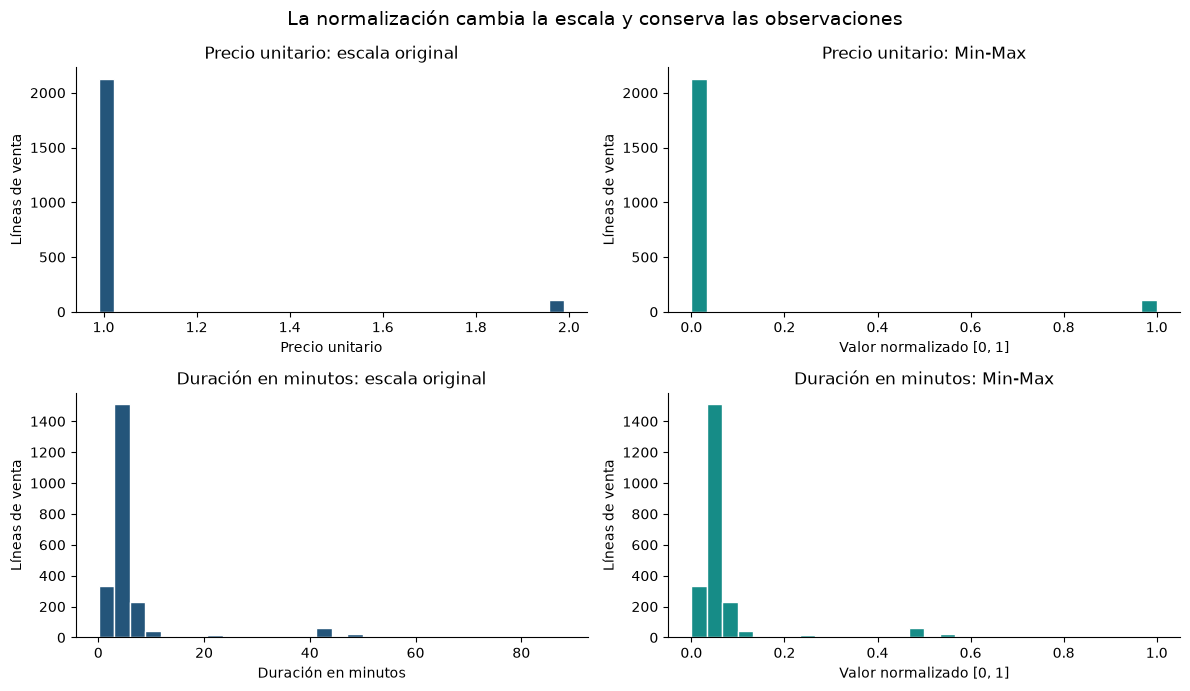

In [17]:
with plt.rc_context({"axes.spines.top": False, "axes.spines.right": False}):
    fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
    etiquetas = ["Precio unitario", "Duración en minutos"]
    for fila, (original, normalizada, etiqueta) in enumerate(zip(
        columnas_escalado, columnas_normalizadas, etiquetas
    )):
        ejes[fila, 0].hist(ventas_transformadas[original], bins=30, color="#24557A", edgecolor="white")
        ejes[fila, 1].hist(ventas_transformadas[normalizada], bins=30, color="#168C87", edgecolor="white")
        ejes[fila, 0].set_title(f"{etiqueta}: escala original")
        ejes[fila, 1].set_title(f"{etiqueta}: Min-Max")
        ejes[fila, 0].set_xlabel(etiqueta)
        ejes[fila, 1].set_xlabel("Valor normalizado [0, 1]")
        for eje in ejes[fila]:
            eje.set_ylabel("Líneas de venta")
    fig.suptitle("La normalización cambia la escala y conserva las observaciones", fontsize=14)
    fig.tight_layout()
    plt.show()

### 3.3. Conversión de variables categóricas a numéricas

Género musical y país de facturación son categorías nominales: no tienen un orden
numérico. Se usa **one-hot encoding**, que crea una columna 0/1 por categoría.
Asignar, por ejemplo, Rock = 1 y Jazz = 2 impondría una distancia sin significado.

Se codifican **Genero** y **PaisFacturacion**, en una copia llamada
**ventas_codificadas**. Se mantienen todos los indicadores para que cada
categoría sea visible; al seleccionar un modelo lineal con intercepto podrá
elegirse una categoría de referencia.

No se codifica el título de cada canción, por su alta cantidad de valores
distintos. PaisCliente coincide con PaisFacturacion en esta fuente, de modo que
no se genera otro bloque redundante de indicadores. Las columnas descriptivas
e identificadoras se conservan para trazabilidad; no por ello deben entrar como
predictores en un modelo.

In [18]:
categoricas_a_codificar = ["Genero", "PaisFacturacion"]
coincidencias_pais = ventas_transformadas["PaisFacturacion"].astype("string").eq(
    ventas_transformadas["PaisCliente"].astype("string")
).sum()
print(f"País de facturación y del cliente coinciden en {coincidencias_pais}/{len(ventas_transformadas)} ventas.")

ventas_codificadas = pd.get_dummies(
    ventas_transformadas,
    columns=categoricas_a_codificar,
    prefix=categoricas_a_codificar,
    drop_first=False,
    dtype="int8"
)

resumen_codificacion = []
columnas_one_hot = []
for columna in categoricas_a_codificar:
    indicadores = [c for c in ventas_codificadas if c.startswith(columna + "_")]
    columnas_one_hot.extend(indicadores)
    assert len(indicadores) == ventas_transformadas[columna].nunique()
    assert ventas_codificadas[indicadores].sum(axis=1).eq(1).all()
    assert ventas_codificadas[indicadores].isin([0, 1]).all().all()
    resumen_codificacion.append({
        "Variable": columna,
        "Categorías observadas": ventas_transformadas[columna].nunique(),
        "Indicadores creados": len(indicadores)
    })

display(pd.DataFrame(resumen_codificacion))
print("Dimensiones del dataset codificado:", ventas_codificadas.shape)
indicadores_muestra = [
    f"{columna}_{ventas_transformadas[columna].iloc[0]}"
    for columna in categoricas_a_codificar
]
display(ventas_codificadas[["IdLineaFactura"] + indicadores_muestra].head(8))

País de facturación y del cliente coinciden en 2240/2240 ventas.


,Variable,Categorías observadas,Indicadores creados
0,Genero,24,24
1,PaisFacturacion,24,24


Dimensiones del dataset codificado: (2240, 65)


,IdLineaFactura,Genero_Rock,PaisFacturacion_Germany
0,1,1,1
1,2,1,1
2,3,1,0
3,4,1,0
4,5,1,0
5,6,1,0
6,7,1,0
7,8,1,0


### 3.4. Selección de variables para correlaciones

La selección se hace por significado, no tomando todas las columnas cuyo tipo
sea numérico:

- **Se excluyen los cinco IDs:** una clave mayor no implica una venta mayor.
- **Se excluye Cantidad si es constante:** sin variación, su correlación no está
  definida. No se sustituye ese resultado por cero.
- Se usa duración en minutos, evitando incluir también milisegundos, que sería
  la misma magnitud en otra unidad. Tampoco se duplican las variables con sus
  versiones normalizadas.
- Se comparan PrecioUnitario, DuracionMinutos e ImporteLinea. La relación entre
  precio e importe se incluye para mostrar explícitamente su dependencia
  matemática, no para presentarla como un descubrimiento.

**Pearson** describe asociación lineal entre valores; **Spearman** utiliza rangos
y permite contrastar si la asociación es monotónica. Ninguno demuestra causalidad.

In [19]:
candidatas_correlacion = ["PrecioUnitario", "Cantidad", "DuracionMinutos", "ImporteLinea"]
resumen_variabilidad = pd.DataFrame({
    "Valores distintos": ventas_transformadas[candidatas_correlacion].nunique(),
    "Desviación estándar": ventas_transformadas[candidatas_correlacion].std()
})
constantes = resumen_variabilidad.index[
    resumen_variabilidad["Valores distintos"] <= 1
].tolist()
columnas_correlacion = [c for c in candidatas_correlacion if c not in constantes]
assert not set(columnas_id).intersection(columnas_correlacion)

display(resumen_variabilidad.round(6))
print("Variables constantes excluidas:", constantes)
print("Variables incluidas:", columnas_correlacion)

correlaciones_pearson = ventas_transformadas[columnas_correlacion].corr(method="pearson")
correlaciones_spearman = ventas_transformadas[columnas_correlacion].corr(method="spearman")
assert np.isfinite(correlaciones_pearson.to_numpy()).all()
assert np.isfinite(correlaciones_spearman.to_numpy()).all()
print("Correlaciones de Pearson:")
display(correlaciones_pearson.round(4))
print("Correlaciones de Spearman:")
display(correlaciones_spearman.round(4))

,Valores distintos,Desviación estándar
PrecioUnitario,2,0.217069
Cantidad,1,0.000000
DuracionMinutos,1846,8.453700
ImporteLinea,2,0.217069


Variables constantes excluidas: ['Cantidad']
Variables incluidas: ['PrecioUnitario', 'DuracionMinutos', 'ImporteLinea']
Correlaciones de Pearson:


,PrecioUnitario,DuracionMinutos,ImporteLinea
PrecioUnitario,1.0000,0.9335,1.0000
DuracionMinutos,0.9335,1.0000,0.9335
ImporteLinea,1.0000,0.9335,1.0000


Correlaciones de Spearman:


,PrecioUnitario,DuracionMinutos,ImporteLinea
PrecioUnitario,1.0000,0.3758,1.0000
DuracionMinutos,0.3758,1.0000,0.3758
ImporteLinea,1.0000,0.3758,1.0000


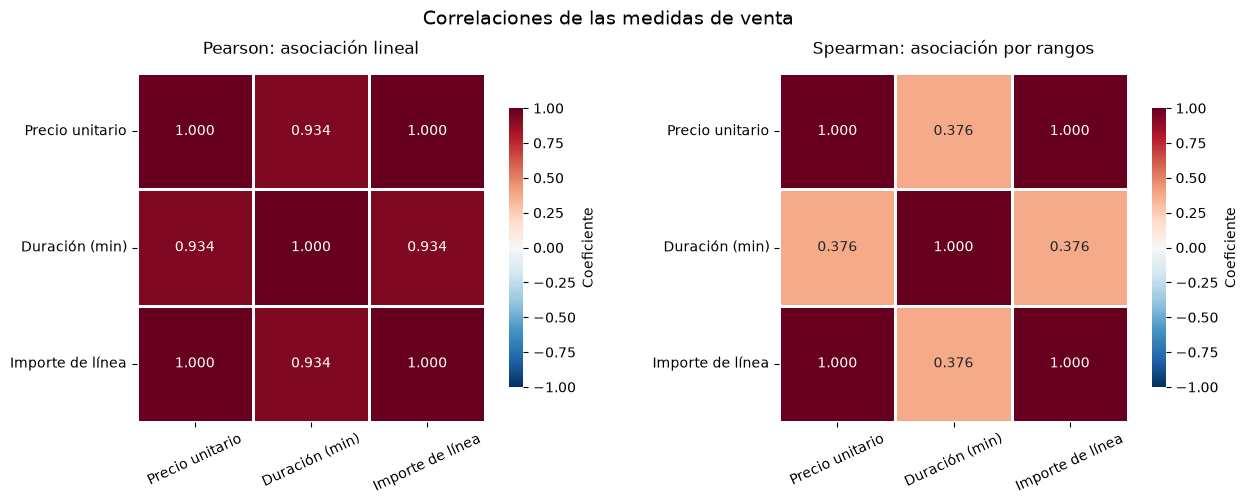

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
etiquetas_correlacion = ["Precio unitario", "Duración (min)", "Importe de línea"]
for eje, matriz, titulo in zip(
    ejes,
    [correlaciones_pearson, correlaciones_spearman],
    ["Pearson: asociación lineal", "Spearman: asociación por rangos"]
):
    sns.heatmap(
        matriz, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1,
        center=0, square=True, linewidths=0.8,
        xticklabels=etiquetas_correlacion, yticklabels=etiquetas_correlacion,
        cbar_kws={"label": "Coeficiente", "shrink": 0.8}, ax=eje
    )
    eje.set_title(titulo, pad=14)
    eje.tick_params(axis="x", rotation=25)
    eje.tick_params(axis="y", rotation=0)
fig.suptitle("Correlaciones de las medidas de venta", fontsize=14)
fig.tight_layout()
plt.show()

,LineasVenta,DuracionMediaMinutos,DuracionMedianaMinutos
PrecioUnitario,,,
0.99,2129,4.456,4.184
1.99,111,40.812,43.510


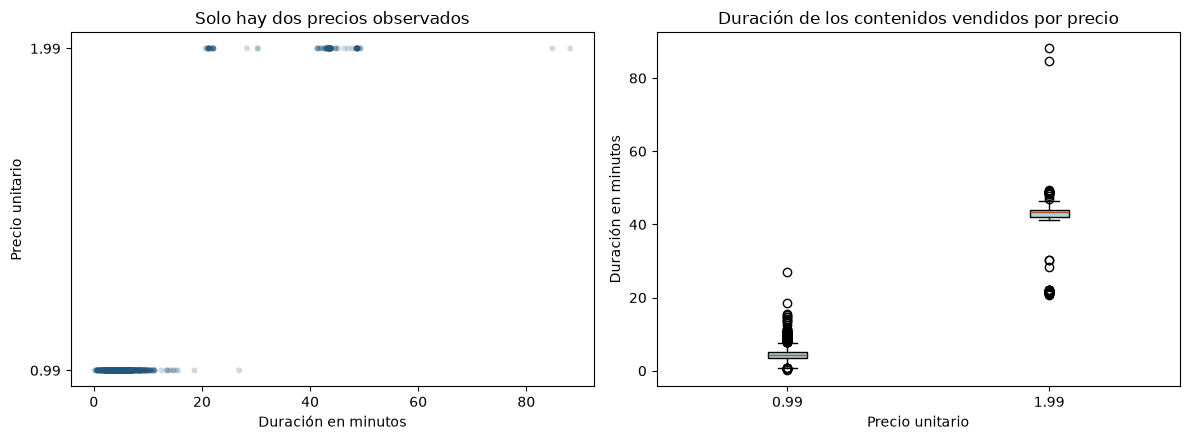

In [21]:
precios_observados = sorted(ventas_transformadas["PrecioUnitario"].unique())
resumen_duracion_precio = ventas_transformadas.groupby("PrecioUnitario").agg(
    LineasVenta=("PrecioUnitario", "size"),
    DuracionMediaMinutos=("DuracionMinutos", "mean"),
    DuracionMedianaMinutos=("DuracionMinutos", "median")
)
display(resumen_duracion_precio.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(
    ventas_transformadas["DuracionMinutos"], ventas_transformadas["PrecioUnitario"],
    alpha=0.22, s=18, color="#24557A", edgecolors="none"
)
ejes[0].set_xlabel("Duración en minutos")
ejes[0].set_ylabel("Precio unitario")
ejes[0].set_yticks(precios_observados)
ejes[0].set_title("Solo hay dos precios observados")

grupos_duracion = [
    ventas_transformadas.loc[
        ventas_transformadas["PrecioUnitario"].eq(precio), "DuracionMinutos"
    ].to_numpy()
    for precio in precios_observados
]
ejes[1].boxplot(
    grupos_duracion, patch_artist=True,
    boxprops={"facecolor": "#A8D8D1"}, medianprops={"color": "#B34B37"}
)
ejes[1].set_xticks(range(1, len(precios_observados) + 1))
ejes[1].set_xticklabels([f"{precio:.2f}" for precio in precios_observados])
ejes[1].set_xlabel("Precio unitario")
ejes[1].set_ylabel("Duración en minutos")
ejes[1].set_title("Duración de los contenidos vendidos por precio")
fig.tight_layout()
plt.show()

### 3.5. Interpretación con el catálogo de origen

Para interpretar las dos bandas de precios se consulta, únicamente como contexto,
el tipo de medio de cada canción o video en las tablas originales. No se imputa
ni se modifica ese catálogo. Se verifican las uniones para no multiplicar ventas.

In [22]:
contexto_precios = ventas_transformadas[[
    "IdLineaFactura", "IdCancion", "PrecioUnitario", "DuracionMinutos"
]].merge(
    tablas["Track"][["TrackId", "MediaTypeId"]],
    left_on="IdCancion", right_on="TrackId", how="left", validate="many_to_one"
).merge(
    tablas["MediaType"][["MediaTypeId", "Name"]].rename(columns={"Name": "TipoMedio"}),
    on="MediaTypeId", how="left", validate="many_to_one"
)
assert len(contexto_precios) == len(ventas_transformadas)
assert contexto_precios["TipoMedio"].notna().all()
resumen_tipo_medio = contexto_precios.groupby(["TipoMedio", "PrecioUnitario"]).agg(
    LineasVenta=("IdLineaFactura", "size"),
    DuracionMediaMinutos=("DuracionMinutos", "mean")
).reset_index()
display(resumen_tipo_medio.round(3))

,TipoMedio,PrecioUnitario,LineasVenta,DuracionMediaMinutos
0,AAC audio file,0.99,3,3.658
1,MPEG audio file,0.99,1976,4.421
2,Protected AAC audio file,0.99,146,4.956
3,Protected MPEG-4 video file,1.99,111,40.812
4,Purchased AAC audio file,0.99,4,4.156


### Resultados de las correlaciones

1. **Cantidad no aporta variabilidad:** todas las líneas tienen una unidad.
   Se conserva para trazabilidad, pero queda fuera de las correlaciones.
2. **PrecioUnitario e ImporteLinea tienen correlación 1.** Es una consecuencia
   de ImporteLinea = PrecioUnitario × Cantidad y de que Cantidad vale 1.
   Usar uno para predecir el otro produciría un resultado trivial por su
   dependencia matemática.
3. **Duración y precio tienen Pearson ≈ 0,934 y Spearman ≈ 0,376.** La diferencia
   importa: el conjunto no muestra una tarifa continua que aumente con cada
   minuto de duración. Hay dos precios: **2.129 líneas a 0,99 y 111 a 1,99**.
   Las duraciones medias son aproximadamente **4,46 y 40,81 minutos**, respectivamente.
4. El catálogo permite contextualizar esa asociación: en estas ventas, las 111
   líneas a 1,99 corresponden a **Protected MPEG-4 video file**. La separación
   entre audio y video explica la composición de los grupos observados; el
   coeficiente por sí solo no demuestra que aumentar la duración cause un
   aumento del precio.
5. Hay **1.984 canciones o contenidos distintos en 2.240 líneas de venta**.
   Estos coeficientes describen las líneas vendidas, con repeticiones de canciones
   y facturas. No se interpretan como pruebas de independencia ni como evidencia
   causal sobre todo el catálogo.

No se agregan IDs a la matriz para obtener más coeficientes: los límites de
variabilidad del dataset también forman parte del resultado del EDA.

In [23]:
# Comprobar la conservación de las entradas y las transformaciones de esta etapa.
pd.testing.assert_frame_equal(ventas_tratadas, ventas_entrada_jeremy)
for nombre, original in tablas_entrada_jeremy.items():
    pd.testing.assert_frame_equal(tablas[nombre], original)

for resultado in [ventas_transformadas, ventas_codificadas]:
    assert len(resultado) == len(ventas_entrada_jeremy)
    assert resultado["IdLineaFactura"].is_unique
    assert resultado["IdLineaFactura"].equals(ventas_entrada_jeremy["IdLineaFactura"])
    assert resultado.isna().sum().sum() == 0
    np.testing.assert_allclose(
        resultado["ImporteLinea"].to_numpy(),
        ventas_entrada_jeremy["ImporteLinea"].to_numpy(), rtol=0, atol=1e-12
    )

np.testing.assert_allclose(
    ventas_transformadas["ImporteLinea"],
    ventas_transformadas["PrecioUnitario"] * ventas_transformadas["Cantidad"],
    rtol=0, atol=1e-12
)
np.testing.assert_allclose(
    ventas_transformadas[columnas_escalado].corr().to_numpy(),
    ventas_transformadas[columnas_normalizadas].corr().to_numpy(),
    rtol=0, atol=1e-12
)

print("Validaciones de Jeremy completadas.")
print("Líneas conservadas:", len(ventas_transformadas))
print("Facturas conservadas:", ventas_transformadas["IdFactura"].nunique())
print("Clientes conservados:", ventas_transformadas["IdCliente"].nunique())
print("Importe conservado:", round(ventas_transformadas["ImporteLinea"].sum(), 2))
print("Indicadores one-hot:", len(columnas_one_hot))
print("Dataset transformado:", ventas_transformadas.shape)
print("Dataset codificado:", ventas_codificadas.shape)
print("Entradas originales sin modificaciones; no se ha exportado el dataset final.")

Validaciones de Jeremy completadas.
Líneas conservadas: 2240
Facturas conservadas: 412
Clientes conservados: 59
Importe conservado: 2328.6
Indicadores one-hot: 48
Dataset transformado: (2240, 19)
Dataset codificado: (2240, 65)
Entradas originales sin modificaciones; no se ha exportado el dataset final.


### 3.6. Continuidad para Miguel

| Variable disponible | Contenido |
|---|---|
| ventas_transformadas | Las ventas con tipos revisados, fecha, duración en minutos, año, mes y las dos columnas normalizadas. Conserva las categorías legibles. |
| ventas_codificadas | Copia de la anterior con género y país de facturación sustituidos por 48 indicadores 0/1. |
| correlaciones_pearson / correlaciones_spearman | Matrices de las medidas cuantitativas seleccionadas. |
| normalizador_jeremy | Parámetros Min-Max del análisis descriptivo. No reutilizar ese ajuste sobre todos los datos para evaluar un modelo. |

Miguel puede continuar desde estas variables para elegir la variable dependiente,
justificar el modelo y exportar **data_process.csv**. Se mantienen identificadores
y columnas descriptivas para seguimiento; antes de modelar deberá seleccionar
qué columnas son predictores y evitar usar el objetivo o sus derivados como entradas.
Si separa entrenamiento y prueba, también debe decidir cómo tratar las repeticiones
por factura, cliente o contenido según la pregunta que quiera evaluar.

**Referencias técnicas:**

- [pandas: conversión de categorías con get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html).
- [pandas: correlaciones Pearson y Spearman](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
- [scikit-learn: MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).
- [scikit-learn: separación de entrenamiento y prueba y fuga de información](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).